# Constraint Satisfaction Problems

The theory is in [README.md](./README.md). This notebook is the seminar: three problems, one
solver, and the two ideas that make the solver fast.

`backtracking_search` is written out for you. Your job is the three functions that plug into it —
choosing which variable to assign, choosing which value to try, and pruning what an assignment
rules out. The homework at the bottom is a different approach entirely.

## Setup

In [1]:
from dataclasses import dataclass
from typing import Callable, Hashable, Optional
from copy import deepcopy
import random
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection

## The four shapes everything is made of

Four types recur in every function below, and two of them are easy to confuse. Naming them once
makes the rest readable — and if you are going to port this to C++, these are the declarations you
need before anything else.

In [2]:
# A variable is whatever names a thing to be decided. It differs per problem --
# "WA" for a region, 3 for a column, (4, 7) for a Sudoku square -- but it is
# always hashable, because it is used as a dictionary key.
Variable = Hashable

# A value is what a variable can be set to: "red", a row number, a digit. Also
# hashable, because values live in sets.
Value = Hashable

# What has been decided so far. Starts empty and holds ONLY the variables that
# have a value; an unassigned variable is simply absent.
Assignment = dict[Variable, Value]

# What each variable is still allowed to be. Holds EVERY variable, always, from
# the moment the problem is built.
Domains = dict[Variable, set[Value]]

# The constraint graph: which variables are constrained with which.
Neighbours = dict[Variable, set[Variable]]

# May A be a at the same time as B is b?
Constraint = Callable[[Variable, Value, Variable, Value], bool]

# Values that inference took out of domains, so a backtrack can put them back.
# Each pair is (the variable it was removed from, the value that was removed).
Pruning = list[tuple[Variable, Value]]

### How each one changes as the search runs

`Assignment` and `Domains` are the pair worth keeping straight. They are not two views of the same
thing: one records decisions, the other records what is still possible.

| | keys | starts as | grows when | shrinks when |
|---|---|---|---|---|
| `Assignment` | only decided variables | `{}` | a variable is assigned | a branch is abandoned |
| `Domains` | **every** variable, always | full domains | a failed branch is undone | inference prunes a value |

So `assignment` grows by exactly one entry per level of recursion. `domains` never gains a key —
only the sets inside it change size.

An unassigned variable is *absent* from `assignment`, not present with some empty value. That is
why `len(assignment) == len(csp.variables)` is the test for a complete solution.

## What a CSP is, in code

Variables, a domain per variable, and a constraint. We only handle **binary** constraints — ones
relating two variables at a time — which is no loss: anything wider can be rewritten this way.

`neighbours[X]` is every variable that shares a constraint with `X`, so it is the constraint graph.
`constraint(A, a, B, b)` answers one question: may `A` be `a` at the same time as `B` is `b`?

One `CSP` object and one solver serve map colouring, N-Queens and Sudoku alike. The solver never
learns which it is looking at.

In [12]:
@dataclass
class CSP:
    variables: list[Variable]
    domains: Domains
    neighbours: Neighbours
    constraint: Constraint

    def consistent(self, var: Variable, value: Value, assignment: Assignment) -> bool:
        """Does var = value clash with anything already assigned?"""
        for other in self.neighbours[var]:
            if other in assignment and not self.constraint(var, value, other, assignment[other]):
                return False
        return True

    def conflicts(self, var: Variable, value: Value, assignment: Assignment) -> int:
        """How many assigned neighbours var = value would clash with."""
        return sum(1 for other in self.neighbours[var]
                   if other in assignment
                   and not self.constraint(var, value, other, assignment[other]))


# The three things backtracking_search lets you swap out. Each stub below is one
# of these, and nothing else in the solver has to change when you supply one.

# which variable to try next; must return an UNASSIGNED one
SelectVariable = Callable[[CSP, Assignment], Variable]

# var's values, in the order to try them
OrderValues = Callable[[CSP, Variable, Assignment], list[Value]]

# prune what this assignment rules out; None means "already hopeless"
Inference = Callable[[CSP, Variable, Value, Assignment], Optional[Pruning]]

## The map of Australia

Variables are the states and territories, values are colours, and the constraint is that two
regions sharing a border may not share a colour.

Note Tasmania. It is an island, so it borders nothing — a variable with an empty neighbour set and
no constraints at all. Any colour will do, and a solver that orders variables sensibly should
dispose of it without effort.

In [13]:
AUSTRALIA_NEIGHBOURS: Neighbours = {
    "WA":  {"NT", "SA"},
    "NT":  {"WA", "SA", "Q"},
    "SA":  {"WA", "NT", "Q", "NSW", "V"},
    "Q":   {"NT", "SA", "NSW"},
    "NSW": {"Q", "SA", "V"},
    "V":   {"SA", "NSW"},
    "T":   set(),           # an island: no land borders
}


def australia_csp(colours: tuple[Value, ...] = ("red", "green", "blue")) -> CSP:
    variables = list(AUSTRALIA_NEIGHBOURS)
    return CSP(
        variables=variables,
        domains={v: set(colours) for v in variables},
        neighbours=AUSTRALIA_NEIGHBOURS,
        constraint=lambda A, a, B, b: a != b,
    )

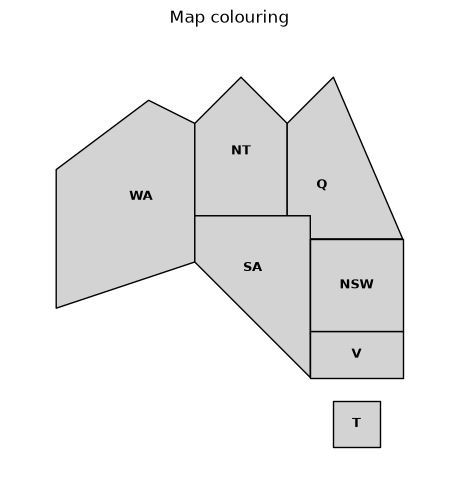

In [14]:
# Rough outlines, enough to recognise the country.
AUSTRALIA_SHAPE = {
    "WA":  [(-2, 0), (-2, 3), (0, 4.5), (1, 4), (1, 2), (1, 1)],
    "NT":  [(1, 4), (2, 5), (3, 4), (3, 2), (1, 2)],
    "Q":   [(3, 4), (3, 2), (3.5, 2), (3.5, 1.5), (5.5, 1.5), (4, 5)],
    "SA":  [(1, 2), (3.5, 2), (3.5, -1.5), (1, 1)],
    "V":   [(3.5, -1.5), (5.5, -1.5), (5.5, -0.5), (3.5, -0.5)],
    "NSW": [(3.5, -0.5), (5.5, -0.5), (5.5, 1.5), (3.5, 1.5)],
    "T":   [(4, -2), (5, -2), (5, -3), (4, -3)],
}


def plot_map(assignment: Assignment, shape=AUSTRALIA_SHAPE, title: str = "Map colouring") -> None:
    fig, ax = plt.subplots(figsize=(6, 6))
    patches = [Polygon(coords, closed=True) for coords in shape.values()]
    collection = PatchCollection(patches, match_original=True)
    collection.set_facecolor([assignment.get(r, "lightgrey") for r in shape])
    collection.set_edgecolor("black")
    ax.add_collection(collection)

    for region, coords in shape.items():
        x = np.mean([c[0] for c in coords])
        y = np.mean([c[1] for c in coords])
        ax.text(x, y, region, fontsize=9, fontweight="bold", ha="center", va="center")

    ax.set_xlim(-3, 6.5)
    ax.set_ylim(-4, 6)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title)
    plt.show()


plot_map({})    # nothing assigned yet

## N-Queens

One variable per column; its value is the row its queen sits in. That framing builds in "no two
queens in a column" for free, so the only constraint left is that no two share a row or a diagonal.

Every column is constrained with every other, so the constraint graph is complete — the opposite
shape from Australia, and the reason backtracking struggles here while local search does not.

In [15]:
def n_queens_csp(n: int = 8) -> CSP:
    variables = list(range(n))                    # the columns
    return CSP(
        variables=variables,
        domains={c: set(range(n)) for c in variables},
        neighbours={c: {d for d in variables if d != c} for c in variables},
        # same row, or on a diagonal
        constraint=lambda A, a, B, b: a != b and abs(A - B) != abs(a - b),
    )


def print_queens(assignment: Assignment, n: int = 8) -> None:
    for row in range(n):
        print(" ".join("Q" if assignment.get(col) == row else "." for col in range(n)))

## Sudoku

Variables are the 81 squares, values are 1 to 9, and a square is constrained with every other
square in its row, its column and its box. A given square is simply a variable whose domain has
one value in it.

The 27 `alldiff` constraints — one per row, column and box — are decomposed here into pairwise
`!=` constraints, which is what lets the same solver handle it.

In [16]:
EASY_SUDOKU: list[list[int]] = [
    [5, 3, 0, 0, 7, 0, 0, 0, 0],
    [6, 0, 0, 1, 9, 5, 0, 0, 0],
    [0, 9, 8, 0, 0, 0, 0, 6, 0],
    [8, 0, 0, 0, 6, 0, 0, 0, 3],
    [4, 0, 0, 8, 0, 3, 0, 0, 1],
    [7, 0, 0, 0, 2, 0, 0, 0, 6],
    [0, 6, 0, 0, 0, 0, 2, 8, 0],
    [0, 0, 0, 4, 1, 9, 0, 0, 5],
    [0, 0, 0, 0, 8, 0, 0, 7, 9],
]


def sudoku_csp(puzzle: list[list[int]]) -> CSP:
    variables = [(r, c) for r in range(9) for c in range(9)]

    def peers(var: Variable) -> set[Variable]:
        r, c = var
        out = {(r, j) for j in range(9)} | {(i, c) for i in range(9)}
        br, bc = 3 * (r // 3), 3 * (c // 3)
        out |= {(i, j) for i in range(br, br + 3) for j in range(bc, bc + 3)}
        out.discard(var)
        return out

    return CSP(
        variables=variables,
        domains={(r, c): ({puzzle[r][c]} if puzzle[r][c] else set(range(1, 10)))
                 for r, c in variables},
        neighbours={v: peers(v) for v in variables},
        constraint=lambda A, a, B, b: a != b,
    )


def print_sudoku(assignment: Assignment) -> None:
    for r in range(9):
        if r and r % 3 == 0:
            print("------+-------+------")
        row = []
        for c in range(9):
            if c and c % 3 == 0:
                row.append("|")
            v = assignment.get((r, c), 0)
            row.append(str(v) if v else ".")
        print(" ".join(row))


print_sudoku({(r, c): EASY_SUDOKU[r][c] for r in range(9) for c in range(9) if EASY_SUDOKU[r][c]})

5 3 . | . 7 . | . . .
6 . . | 1 9 5 | . . .
. 9 8 | . . . | . 6 .
------+-------+------
8 . . | . 6 . | . . 3
4 . . | 8 . 3 | . . 1
7 . . | . 2 . | . . 6
------+-------+------
. 6 . | . . . | 2 8 .
. . . | 4 1 9 | . . 5
. . . | . 8 . | . 7 9


## Backtracking search

Depth-first, one variable at a time. The thing that makes it more than plain DFS: the order you
assign variables in does not matter, so at each step you pick **one** unassigned variable and try
only its values — not every variable's values. That alone takes the branching factor from `n x d`
down to `d`.

This one is written out, as the shape the rest of the week plugs into. Three things to notice:

- the two naive choices at the top — first unassigned variable, values in any order — are exactly
  the two things `mrv` and `lcv` will replace
- `inference` is allowed to say "this is already hopeless" by returning `None`, which is how
  forward checking prunes a branch before recursing into it
- every prune is undone when a branch **fails**. A CSP solver mutates the domains as it goes, so
  putting them back is not an optimisation, it is what keeps the search correct. Note the asymmetry:
  a search that *succeeds* returns straight up through the recursion without undoing anything, so
  the domains keep the prunings made along the winning path. Build a fresh `CSP` if you want to
  solve the same problem twice

In [17]:
def backtracking_search(csp: CSP,
                        select_variable: Optional[SelectVariable] = None,
                        order_values: Optional[OrderValues] = None,
                        inference: Optional[Inference] = None) -> Optional[Assignment]:
    """Assign variables one at a time, undoing an assignment when it leads nowhere.

    select_variable(csp, assignment)        -> which variable to try next
    order_values(csp, var, assignment)      -> the values to try, in order
    inference(csp, var, value, assignment)  -> prunings to apply, or None if this
                                               assignment is already hopeless

    Leave any of them as None to use the naive choice.

    Returns the assignment as a dict, or None if there is no solution.
    Record how many assignments you made in backtracking_search.assignments.
    """
    backtracking_search.assignments = 0

    # The naive choices, used when nothing better is supplied. Each of the
    # heuristics you write later is a drop-in replacement for one of these.
    def first_unassigned(csp: CSP, assignment: Assignment) -> Variable:
        return next(v for v in csp.variables if v not in assignment)

    def in_any_order(csp: CSP, var: Variable, assignment: Assignment) -> list[Value]:
        return list(csp.domains[var])

    select = select_variable or first_unassigned
    order = order_values or in_any_order

    def backtrack(assignment: Assignment) -> Optional[Assignment]:
        # Every variable has a value and nothing was ever assigned inconsistently,
        # so this is a solution.
        if len(assignment) == len(csp.variables):
            return assignment

        var = select(csp, assignment)

        for value in order(csp, var, assignment):
            if not csp.consistent(var, value, assignment):
                continue

            assignment[var] = value
            backtracking_search.assignments += 1

            # Inference may prune other domains, and may discover straight away
            # that this assignment cannot lead anywhere.
            removed: Pruning = []
            hopeless = False
            if inference is not None:
                removed = inference(csp, var, value, assignment)
                hopeless = removed is None

            if not hopeless:
                result = backtrack(assignment)
                if result is not None:
                    return result

            # This value did not work out. Put back everything inference took,
            # then unassign, and try the next value.
            for other, gone in (removed or []):
                csp.domains[other].add(gone)
            del assignment[var]

        # No value worked. The caller has to change something above us.
        return None

    return backtrack({})

{'WA': 'blue', 'NT': 'red', 'SA': 'green', 'Q': 'blue', 'NSW': 'red', 'V': 'blue', 'T': 'blue'}


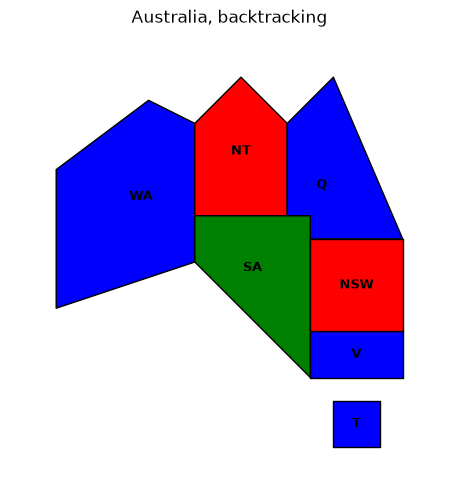

In [18]:
csp = australia_csp()
solution = backtracking_search(csp)
print(solution)
plot_map(solution or {}, title="Australia, backtracking")

In [19]:
solution = backtracking_search(n_queens_csp(8))
print(f"{backtracking_search.assignments} assignments")
print_queens(solution, 8)

113 assignments
Q . . . . . . .
. . . . . . Q .
. . . . Q . . .
. . . . . . . Q
. Q . . . . . .
. . . Q . . . .
. . . . . Q . .
. . Q . . . . .


### Why the rest of this seminar exists

Australia falls out in 7 assignments — one per variable, no backtracking at all. Both of those
look fine, and neither tells you anything.

Sudoku is where it shows. Run plain backtracking on `EASY_SUDOKU` and it needs about **14.7 million
assignments and a minute**, on a puzzle a person does over coffee. It is not stuck, it is blind: it
works left to right along the top row and only finds a contradiction after filling in dozens of
squares that had nothing to do with it.

With the three functions below it takes **81 assignments in five milliseconds**. Eighty-one
assignments for eighty-one squares means it never backtracked once.

| | assignments | time |
|---|---:|---:|
| sudoku, plain backtracking | 14,740,819 | 61 s |
| sudoku, with the three below | 81 | 0.005 s |

Worth running the slow one yourself once, so the minute is real rather than a number in a table.
Then never again.

## Choosing the variable: MRV and degree

**Minimum remaining values** — take the variable with the fewest values left. If it is going to
fail, fail now rather than ten assignments deeper.

**Degree** — break ties by taking the variable constrained with the most *unassigned* variables.
With nothing assigned yet every domain is full, so MRV cannot choose and degree does the work.
On Australia it should pick South Australia first, which borders five of the other six.

In [ ]:
def mrv(csp: CSP, assignment: Assignment) -> Variable:
    """The unassigned variable with the fewest legal values left.

    Break ties with the degree heuristic: most constraints on unassigned
    variables.

    Hint: this is a min() over the unassigned variables. The key can be a tuple,
    and tuples compare left to right -- so domain size decides, and degree only
    gets a say on a tie.
    """
    # TODO
    raise NotImplementedError

## Choosing the value: LCV

**Least constraining value** — try the value that rules out the fewest choices for the neighbours.

Note that this is the opposite instinct from MRV, and deliberately so. Every variable has to work
out, so probe the fragile one first; only one *value* has to work out, so try the accommodating one
first.

In [ ]:
def lcv(csp: CSP, var: Variable, assignment: Assignment) -> list[Value]:
    """var's values, ordered so the one ruling out fewest neighbour options comes first.

    Hint: this is a sorted() over csp.domains[var]. For each value, count how
    many of its undecided neighbours' remaining values it would make impossible.
    """
    # TODO
    raise NotImplementedError

## Inference: forward checking

When you assign a variable, remove that value from the domains of its unassigned neighbours. If a
domain goes empty, this branch is already dead — stop now rather than discovering it later.

Return the prunings you made so the caller can undo them on backtrack, and `None` to mean "this
assignment cannot work".

In [ ]:
def forward_check(csp: CSP, var: Variable, value: Value,
                  assignment: Assignment) -> Optional[Pruning]:
    """Prune value from unassigned neighbours' domains.

    Returns a list of (variable, removed_value) pairs so the caller can put them
    back, or None if some domain was emptied.

    Two things to be careful about: iterate over a copy of the domain you are
    about to change, and if you do empty a domain, undo your own prunings before
    returning None -- the caller will not do it for you.
    """
    # TODO
    raise NotImplementedError

## Putting it together

Count assignments rather than seconds: it is the number that means the same thing on any machine,
and it is what the heuristics are actually changing.

In [ ]:
print(f"{'setup':40} {'assignments':>12} {'seconds':>9}")
print("-" * 64)


def timed(label, fn):
    start = time.time()
    fn()
    print(f"{label:40} {backtracking_search.assignments:>12} {time.time() - start:9.3f}")


timed("australia, plain",
      lambda: backtracking_search(australia_csp()))
timed("australia, MRV + LCV + forward check",
      lambda: backtracking_search(australia_csp(), mrv, lcv, forward_check))
timed("8 queens, plain",
      lambda: backtracking_search(n_queens_csp(8)))
timed("8 queens, MRV + LCV + forward check",
      lambda: backtracking_search(n_queens_csp(8), mrv, lcv, forward_check))
timed("sudoku, MRV + LCV + forward check",
      lambda: backtracking_search(sudoku_csp(EASY_SUDOKU), mrv, lcv, forward_check))

## Homework: min-conflicts

Everything above builds a solution from nothing, one variable at a time, and backs up when it gets
stuck. Local search does the opposite: it starts with a **complete** assignment — almost certainly
wrong — and repairs it.

    pick a variable that is in conflict
    give it the value that leaves it in conflict with the fewest others
    repeat

That is the whole idea. It cannot prove a problem unsolvable, and it can get stuck somewhere every
move makes worse, so give it a step budget.

It is the natural fit for N-Queens, where backtracking struggles at any real size. Get it working
at `n = 8`, then try `n = 50` and `n = 200` and watch what happens to the number of steps as the
board grows. That number is the interesting one, not the clock.

Two things worth thinking about while you write it:

- what you start from matters as much as the repair rule. A random starting assignment and a
  greedy one — each variable taking its least-conflicting value as you go — behave very differently
- ties need breaking at random, or the search walks the same small loop for ever

In [ ]:
def min_conflicts(csp: CSP, max_steps: int = 10000) -> Optional[Assignment]:
    """Repair a complete assignment until it has no conflicts.

    Start from a complete assignment. Then, repeatedly: pick a variable that is
    currently in conflict, and reassign it to the value that leaves the fewest
    conflicts.

    Returns the assignment, or None if max_steps ran out.
    Record the steps taken in min_conflicts.steps.
    """
    # TODO
    raise NotImplementedError

In [ ]:
random.seed(0)
solution = min_conflicts(n_queens_csp(8))
print(f"{min_conflicts.steps} steps")
print_queens(solution, 8)

In [ ]:
print(f"  {'n':>5} {'steps':>7} {'seconds':>9}")
for n in (8, 50, 200):
    random.seed(0)
    start = time.time()
    solution = min_conflicts(n_queens_csp(n))
    print(f"  {n:5} {min_conflicts.steps:7} {time.time() - start:9.2f}"
          f"   {'solved' if solution else 'gave up'}")